In [ ]:
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import regression_utils as ru
import kWh_consumption as kc
import plotly.express as px

import warnings

# Ignore all warnings
warnings.filterwarnings("ignore")


# Import data

In [ ]:
# appliance count
appliance_count = pd.read_csv('../data/processed/appliance_count.csv')
appliance_count['camera'] = appliance_count.still_camera + appliance_count.video_camera
non_electric_count = pd.read_csv('../data/processed/non_electric_count.csv')
appliance_presence = pd.read_csv('../data/processed/appliance_presence_HH.csv')

# all data
data = pd.read_csv('../data/processed/sample_qsel_11_21_23.csv')
data_clipped = data[['hhid','monthly_expenses_qsel','outage_duration_2016', 'outage_duration_2017','outage_freq_2016', 'outage_freq_2017',
                     'female','members','num_rooms','hh_female', 'Children','Seniors','log_monthly_expenses_qsel']] # priority columns 'rural',

# HH electricity consumption
kwh_hhs = data[['hhid','nisr_m_electricity_kWh','reg_m_electricity_kWhs']].dropna(subset='nisr_m_electricity_kWh')



# Household features

In [ ]:

appliances_cols = ['hhid', 'Radio', 'TV', 'satellite_dish', 'dvd_player', 'decoder',
       'music_syst', 'cooker', 'laundry_mach', 'electric_fan', 'fridge',
        'hotplate', 'camera', 'printer', 'computer', 'Mobile_phones',
       'smart_phones',
    #    'num_rooms'
       ]
appliances = non_electric_count[['hhid','Sewing_machine','Water_Filter']].merge(appliance_count[appliances_cols],how='inner').set_index('hhid') # merge seemingly non electric and electric
appliances['analogue_phones'] = appliances.Mobile_phones - appliances.smart_phones # add column for analogue phones
columns = appliances.columns.tolist()+['num_rooms']
appliances = appliances.reset_index().merge(data_clipped)


# Group HHs by number of appiances of @ kind owned
# for col in columns:
#     appliances[f'{col}_grp']=appliances.apply(lambda x: kc.appliance_groups(x[f'{col}']), axis=1)


# Consumption

In [ ]:
grid = data[['hhid','grid']]
grid_hhids=grid[grid.grid==1].hhid.tolist()
appliances_only_grid = appliances[appliances.hhid.isin(grid_hhids)]


In [ ]:

appliance_monthly_consumption = {
    'laundry_mach':36.675,
    'TV':5.209,
    'smart_phones':2.148,
    'analogue_phones':0.595,
    'hotplate':15.601,
    'fridge':19.585,
    'num_rooms':0.713,
}

key_appliances = ['laundry_mach','TV','smart_phones','analogue_phones','hotplate','fridge','num_rooms']
grid = data[['hhid','grid']]
grid_hhids=grid[grid.grid==1].hhid.tolist()
appliances_only_grid = appliances[appliances.hhid.isin(grid_hhids)]
appliances_only_grid['appliance_check'] = appliances_only_grid[['laundry_mach', 'TV', 'smart_phones', 'analogue_phones', 'hotplate', 'fridge']].sum(axis=1)

# Multiply each appliance by its corresponding consumption value
for appliance, consumption in appliance_monthly_consumption.items():
    appliances_only_grid[f'{appliance}'] = appliances_only_grid[appliance] * consumption

# Calculate total consumption for each appliance across households
total_consumption = appliances_only_grid[['laundry_mach', 'TV', 'smart_phones', 'analogue_phones', 'hotplate', 'fridge', 'num_rooms']].sum()
total_consumption = total_consumption.reset_index().rename(columns={'index':'Appliances',0:'Aggregate_hh_consumption'}).replace({'laundry_mach':'laundry Machines',
'smart_phones':'smart phones',
'analogue_phones':'feature phones',
'num_rooms':'lights'
})
appliances_only_grid['monthly_hh_kWhs'] = appliances_only_grid[['laundry_mach', 'TV', 'smart_phones', 'analogue_phones', 'hotplate', 'fridge', 'num_rooms']].sum(axis=1)
key_appliances = appliances_only_grid[['hhid','laundry_mach', 'TV', 'smart_phones', 'analogue_phones', 'hotplate', 'fridge', 'num_rooms','monthly_hh_kWhs','appliance_check']]
key_appliances[key_appliances.appliance_check>0].monthly_hh_kWhs.median()

6.308

In [ ]:
# df_plotly = df.reset_index()
# legend = ['Laundry Machine', 'TV', 'Smart Phone', 'Feature Phones', 'Hotplate', 'Fridge', 'Lights']
# df_plotly['appliance_names'] = legend

# Create the pie chart
fig = px.pie(total_consumption, values='Aggregate_hh_consumption', names='Appliances',)

# Update trace settings for better label readability and positioning
fig.update_traces(
    textposition='inside',
    textinfo='percent+label',
    textfont_size=26,  # Adjust font size inside the pie
    pull=[0.1, 0, 0, 0, 0.05, 0, 0]  # Slightly pull the first and fifth slices for emphasis
)

# Update layout for overall aesthetics
fig.update_layout(
    autosize=False,
    width=1000,
    height=800,
    legend=dict(
        font=dict(family="Courier", size=22, color="black"),
        orientation="h",  # Horizontal legend for better space usage
        x=0.5,  # Center the legend
        xanchor="center",
        y=-0.1  # Move the legend below the chart
    ),
    margin=dict(t=50, b=100, l=50, r=50),  # Adjust margins for better spacing
#     title=dict(
#         text='Appliance Wattage Distribution',
#         font=dict(size=28),
#         x=0.5,  # Center title
#         xanchor='center'
#     )
)

# Show the pie chart
fig.show()

In [ ]:
# Create new column 'low_income' based on expenditure
median_expenditure = appliances_only_grid.monthly_expenses_qsel.median()
appliances_only_grid['low_income'] = np.where(appliances_only_grid['monthly_expenses_qsel'] < median_expenditure, 1, 0)

low_income_hhids = appliances_only_grid[appliances_only_grid.low_income==0]


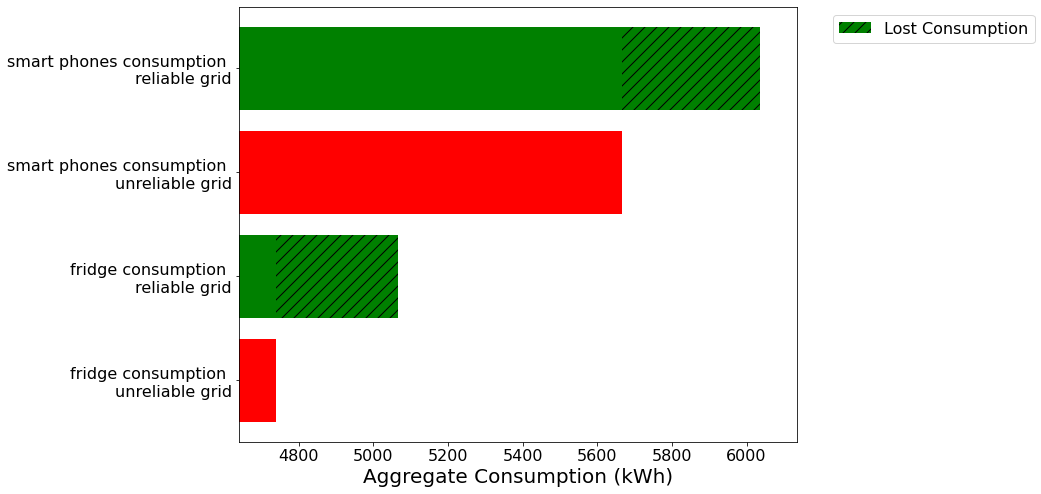

In [ ]:
low_income_hhids = appliances_only_grid[appliances_only_grid.low_income==0]
# Appliances and their corresponding reliability multipliers
appliances = ['fridge', 'smart_phones']
# appliances = ['TV', 'smart_phones']
appliance_name_dict = {'fridge':'fridge', 'TV':'TV', 'smart_phones':'smart phones'}
appliance_reliability_dict = {'TV': 1.064, 'smart_phones': 1.065, 'fridge': 1.069}

# Initialize a new figure
plt.figure(figsize=(10, 8))
fontsize = 20
tcksize = 16

# Boolean flag to track if the label has been added to the legend
label_added = False

# Loop through each appliance to plot its bars
for appliance in appliances:
    # Calculate current total consumption and full reliability consumption
    total_current_consumption = low_income_hhids[f'{appliance}'].sum()
    total_full_reliability_consumption = total_current_consumption * appliance_reliability_dict[f'{appliance}']

    # Set labels dynamically based on the appliance
    labels = [f'{appliance_name_dict[appliance]} consumption \nunreliable grid', f'{appliance_name_dict[appliance]} consumption \nreliable grid']
    values = [total_current_consumption, total_full_reliability_consumption]

    # Plot horizontal bar for Unreliable Grid
    plt.barh(labels[0], values[0], color='red')

    # Plot horizontal bar for Reliable Grid with cross-hatching for the portion above the threshold
    plt.barh(labels[1], total_current_consumption, color='green')  # Base portion

    # Add hatched portion only once in the legend
    if not label_added:
        plt.barh(labels[1], total_full_reliability_consumption - total_current_consumption,
                 left=total_current_consumption, color='green', hatch='//', label='Lost Consumption')  # Hatched portion
        label_added = True  # Mark that the label has been added
    else:
        plt.barh(labels[1], total_full_reliability_consumption - total_current_consumption,
                 left=total_current_consumption, color='green', hatch='//')  # Hatched portion without label

# Customize the plot
plt.xlabel('Aggregate Consumption (kWh)', fontsize=fontsize)
plt.ylabel('', fontsize=fontsize)
plt.xticks(fontsize=tcksize)
plt.yticks(fontsize=tcksize)
plt.xlim(min(low_income_hhids[appliances].sum())-100, max([low_income_hhids[f'{a}'].sum() * appliance_reliability_dict[a] for a in appliances]) + 100)

plt.legend(fontsize=16, bbox_to_anchor=(1.05, 1), loc='upper left')

# Show the plot
plt.show()


### OLD